In [ ]:
!pip install scipy scikit-learn matplotlib

In [ ]:
import os
import numpy as np
import scipy.io as sio
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import copy
import random

In [ ]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
base_path = "/content/drive/MyDrive/ks20"

In [ ]:
import os
print(os.listdir("/content/drive/MyDrive"))

In [ ]:
import os
print(os.listdir("/content/drive/MyDrive/ks20"))

In [ ]:
print(os.listdir("/content/drive/MyDrive/ks20/KS20_Vislab_MultiView_dataset"))

In [ ]:
import os

base_path = "/content/drive/MyDrive/ks20/KS20_Vislab_MultiView_dataset"
directions = ['frontal', 'left_lateral', 'right_lateral', 'left_diagonal', 'right_diagonal']

for d in directions:
    dpath = os.path.join(base_path, d)
    print(f"\nDirection: {d}")
    print(os.listdir(dpath)[:20])

In [ ]:
import os

base_path = "/content/drive/MyDrive/ks20/KS20_Vislab_MultiView_dataset"
directions = ['frontal', 'left_lateral', 'right_lateral', 'left_diagonal', 'right_diagonal']

data = []

for d in directions:
    dpath = os.path.join(base_path, d)

    for file in os.listdir(dpath):
        if file.endswith(".mat"):
            subject_id = int(file.split("body")[1].split(".")[0])
            seq_id = file.split("_")[0]   # gc1 / gc2 / gc3

            data.append({
                "path": os.path.join(dpath, file),
                "subject": subject_id,
                "direction": d,
                "seq": seq_id
            })

print("Total samples:", len(data))
print(data[:5])

Total samples: 300
[{'path': '/content/drive/MyDrive/ks20/KS20_Vislab_MultiView_dataset/frontal/gc3_body9.mat', 'subject': 9, 'direction': 'frontal', 'seq': 'gc3'}, {'path': '/content/drive/MyDrive/ks20/KS20_Vislab_MultiView_dataset/frontal/gc2_body11.mat', 'subject': 11, 'direction': 'frontal', 'seq': 'gc2'}, {'path': '/content/drive/MyDrive/ks20/KS20_Vislab_MultiView_dataset/frontal/gc1_body22.mat', 'subject': 22, 'direction': 'frontal', 'seq': 'gc1'}, {'path': '/content/drive/MyDrive/ks20/KS20_Vislab_MultiView_dataset/frontal/gc3_body15.mat', 'subject': 15, 'direction': 'frontal', 'seq': 'gc3'}, {'path': '/content/drive/MyDrive/ks20/KS20_Vislab_MultiView_dataset/frontal/gc1_body15.mat', 'subject': 15, 'direction': 'frontal', 'seq': 'gc1'}]


In [ ]:
from collections import defaultdict

subject_counts = defaultdict(int)

for item in data:
    subject_counts[item["subject"]] += 1

for sid in sorted(subject_counts.keys()):
    print(f"Subject {sid}: {subject_counts[sid]} samples")

Subject 1: 15 samples
Subject 2: 15 samples
Subject 3: 15 samples
Subject 4: 15 samples
Subject 7: 15 samples
Subject 8: 15 samples
Subject 9: 15 samples
Subject 11: 15 samples
Subject 12: 15 samples
Subject 13: 15 samples
Subject 14: 15 samples
Subject 15: 15 samples
Subject 16: 15 samples
Subject 17: 15 samples
Subject 19: 15 samples
Subject 20: 15 samples
Subject 21: 15 samples
Subject 22: 15 samples
Subject 23: 15 samples
Subject 24: 15 samples


In [ ]:
import numpy as np
import scipy.io as sio

In [ ]:
sample_path = data[0]["path"]
mat = sio.loadmat(sample_path)

print(mat.keys())

dict_keys(['__header__', '__version__', '__globals__', 'gc'])


In [ ]:
import os

for d in directions:
    dpath = os.path.join(base_path, d)
    mat_files = []
    for root, _, files in os.walk(dpath):
        for f in files:
            if f.endswith(".mat"):
                mat_files.append(os.path.join(root, f))
    print(f"\n{d}: {len(mat_files)} mat files")
    for f in mat_files[:5]:
        print(" ", f)


frontal: 60 mat files
  /content/drive/MyDrive/ks20/KS20_Vislab_MultiView_dataset/frontal/gc3_body9.mat
  /content/drive/MyDrive/ks20/KS20_Vislab_MultiView_dataset/frontal/gc2_body11.mat
  /content/drive/MyDrive/ks20/KS20_Vislab_MultiView_dataset/frontal/gc1_body22.mat
  /content/drive/MyDrive/ks20/KS20_Vislab_MultiView_dataset/frontal/gc3_body15.mat
  /content/drive/MyDrive/ks20/KS20_Vislab_MultiView_dataset/frontal/gc1_body15.mat

left_lateral: 60 mat files
  /content/drive/MyDrive/ks20/KS20_Vislab_MultiView_dataset/left_lateral/gc1_body1.mat
  /content/drive/MyDrive/ks20/KS20_Vislab_MultiView_dataset/left_lateral/gc2_body1.mat
  /content/drive/MyDrive/ks20/KS20_Vislab_MultiView_dataset/left_lateral/gc3_body1.mat
  /content/drive/MyDrive/ks20/KS20_Vislab_MultiView_dataset/left_lateral/gc1_body2.mat
  /content/drive/MyDrive/ks20/KS20_Vislab_MultiView_dataset/left_lateral/gc3_body2.mat

right_lateral: 60 mat files
  /content/drive/MyDrive/ks20/KS20_Vislab_MultiView_dataset/right_later

In [ ]:
from scipy.io import loadmat

sample_file = "/content/drive/MyDrive/ks20/KS20_Vislab_MultiView_dataset/frontal/gc2_body13.mat"
mat_data = loadmat(sample_file)

print("Keys:", mat_data.keys())

for k in mat_data:
    if not k.startswith("__"):
        arr = mat_data[k]
        print("\nKEY:", k)
        print("TYPE:", type(arr))
        print("SHAPE:", getattr(arr, "shape", None))
        print("DTYPE:", getattr(arr, "dtype", None))

Keys: dict_keys(['__header__', '__version__', '__globals__', 'gc'])

KEY: gc
TYPE: <class 'numpy.ndarray'>
SHAPE: (1, 41)
DTYPE: [('time', 'O'), ('counter', 'O'), ('body', 'O'), ('floor', 'O')]


In [ ]:
gc = mat_data["gc"]

frame0 = gc[0, 0]

print("TYPE:", type(frame0))
print("DTYPE:", frame0.dtype)
print("FIELD NAMES:", frame0.dtype.names)
print("\nFRAME0:\n", frame0)

TYPE: <class 'numpy.void'>
DTYPE: [('time', 'O'), ('counter', 'O'), ('body', 'O'), ('floor', 'O')]
FIELD NAMES: ('time', 'counter', 'body', 'floor')

FRAME0:
 (array([[1.46980607e+12]]), array([[0]], dtype=uint8), array([[(array([[array(['72057594037930437'], dtype='<U17')]], dtype=object), array([[(array([[array(['0'], dtype='<U1')]], dtype=object), array([[array(['2'], dtype='<U1')]], dtype=object), array([[array(['0.142007'], dtype='<U8'),
                        array(['-0.239178'], dtype='<U9'),
                        array(['3.320045'], dtype='<U8')]], dtype=object), array([[array(['-0.008099'], dtype='<U9'),
                        array(['0.997217'], dtype='<U8'),
                        array(['-0.071339'], dtype='<U9'),
                        array(['-0.020091'], dtype='<U9')]], dtype=object))                                                                                       ,
                (array([[array(['1'], dtype='<U1')]], dtype=object), array([[array(['2'], dtype

In [ ]:
body = frame0["body"]

print("TYPE:", type(body))
print("SHAPE:", getattr(body, "shape", None))
print("DTYPE:", getattr(body, "dtype", None))
print("\nBODY:\n", body)

TYPE: <class 'numpy.ndarray'>
SHAPE: (1, 1)
DTYPE: [('id', 'O'), ('joints', 'O')]

BODY:
 [[(array([[array(['72057594037930437'], dtype='<U17')]], dtype=object), array([[(array([[array(['0'], dtype='<U1')]], dtype=object), array([[array(['2'], dtype='<U1')]], dtype=object), array([[array(['0.142007'], dtype='<U8'),
                  array(['-0.239178'], dtype='<U9'),
                  array(['3.320045'], dtype='<U8')]], dtype=object), array([[array(['-0.008099'], dtype='<U9'),
                  array(['0.997217'], dtype='<U8'),
                  array(['-0.071339'], dtype='<U9'),
                  array(['-0.020091'], dtype='<U9')]], dtype=object))                                                                                       ,
          (array([[array(['1'], dtype='<U1')]], dtype=object), array([[array(['2'], dtype='<U1')]], dtype=object), array([[array(['0.135689'], dtype='<U8'),
                  array(['0.089566'], dtype='<U8'),
                  array(['3.272891'], dtype='<

In [ ]:
body_u = body[0, 0]

print("TYPE:", type(body_u))
print("DTYPE:", body_u.dtype)
print("FIELD NAMES:", body_u.dtype.names)
print("\nBODY_U:\n", body_u)

TYPE: <class 'numpy.void'>
DTYPE: [('id', 'O'), ('joints', 'O')]
FIELD NAMES: ('id', 'joints')

BODY_U:
 (array([[array(['72057594037930437'], dtype='<U17')]], dtype=object), array([[(array([[array(['0'], dtype='<U1')]], dtype=object), array([[array(['2'], dtype='<U1')]], dtype=object), array([[array(['0.142007'], dtype='<U8'),
                array(['-0.239178'], dtype='<U9'),
                array(['3.320045'], dtype='<U8')]], dtype=object), array([[array(['-0.008099'], dtype='<U9'),
                array(['0.997217'], dtype='<U8'),
                array(['-0.071339'], dtype='<U9'),
                array(['-0.020091'], dtype='<U9')]], dtype=object))                                                                                       ,
        (array([[array(['1'], dtype='<U1')]], dtype=object), array([[array(['2'], dtype='<U1')]], dtype=object), array([[array(['0.135689'], dtype='<U8'),
                array(['0.089566'], dtype='<U8'),
                array(['3.272891'], dtype='<U8'

In [ ]:
joints = body_u["joints"]

print("TYPE:", type(joints))
print("SHAPE:", getattr(joints, "shape", None))
print("DTYPE:", getattr(joints, "dtype", None))
print("\nJOINTS:\n", joints)

TYPE: <class 'numpy.ndarray'>
SHAPE: (1, 25)
DTYPE: [('type', 'O'), ('tracking', 'O'), ('position', 'O'), ('orientation', 'O')]

JOINTS:
 [[(array([[array(['0'], dtype='<U1')]], dtype=object), array([[array(['2'], dtype='<U1')]], dtype=object), array([[array(['0.142007'], dtype='<U8'),
          array(['-0.239178'], dtype='<U9'),
          array(['3.320045'], dtype='<U8')]], dtype=object), array([[array(['-0.008099'], dtype='<U9'),
          array(['0.997217'], dtype='<U8'),
          array(['-0.071339'], dtype='<U9'),
          array(['-0.020091'], dtype='<U9')]], dtype=object))
  (array([[array(['1'], dtype='<U1')]], dtype=object), array([[array(['2'], dtype='<U1')]], dtype=object), array([[array(['0.135689'], dtype='<U8'),
          array(['0.089566'], dtype='<U8'),
          array(['3.272891'], dtype='<U8')]], dtype=object), array([[array(['-0.007029'], dtype='<U9'),
          array(['0.996804'], dtype='<U8'),
          array(['-0.071453'], dtype='<U9'),
          array(['-0.035034

In [ ]:
joints_u = joints[0, 0]

print("TYPE:", type(joints_u))
print("SHAPE:", getattr(joints_u, "shape", None))
print("DTYPE:", getattr(joints_u, "dtype", None))
print("FIELD NAMES:", joints_u.dtype.names)

TYPE: <class 'numpy.void'>
SHAPE: ()
DTYPE: [('type', 'O'), ('tracking', 'O'), ('position', 'O'), ('orientation', 'O')]
FIELD NAMES: ('type', 'tracking', 'position', 'orientation')


In [ ]:
joint_position = joints_u['position']

# The position data is an array of objects (arrays of strings), so we need to extract and convert them.
# The inner arrays contain single string values, so we convert each to float.
position_coords = np.array([float(coord[0]) for coord in joint_position[0]], dtype=float)

print("TYPE (joint_position):", type(joint_position))
print("SHAPE (joint_position):", getattr(joint_position, "shape", None))
print("DTYPE (joint_position):", getattr(joint_position, "dtype", None))
print("\nJOINT_POSITION:", joint_position)

print("\nTYPE (position_coords):", type(position_coords))
print("SHAPE (position_coords):", getattr(position_coords, "shape", None))
print("DTYPE (position_coords):", getattr(position_coords, "dtype", None))
print("\nPOSITION_COORDS:", position_coords)

TYPE (joint_position): <class 'numpy.ndarray'>
SHAPE (joint_position): (1, 3)
DTYPE (joint_position): object

JOINT_POSITION: [[array(['0.142007'], dtype='<U8') array(['-0.239178'], dtype='<U9')
  array(['3.320045'], dtype='<U8')]]

TYPE (position_coords): <class 'numpy.ndarray'>
SHAPE (position_coords): (3,)
DTYPE (position_coords): float64

POSITION_COORDS: [ 0.142007 -0.239178  3.320045]


In [ ]:
import numpy as np
from scipy.io import loadmat

def extract_xyz_from_joint(joint):
    pos = joint[2]   # position field

    x = float(np.asarray(pos[0][0]).item())
    y = float(np.asarray(pos[0][1]).item())
    z = float(np.asarray(pos[0][2]).item())

    return [x, y, z]

def load_ks20_skeleton(mat_path):
    mat = loadmat(mat_path)
    gc = mat["gc"]

    frames = []

    for t in range(gc.shape[1]):
        try:
            frame = gc[0, t]
            body = frame["body"][0, 0]

            # THIS is the important correction
            joint_matrix = body["joints"]   # shape should be (1, 25)

            frame_joints = []
            for j in range(joint_matrix.shape[1]):
                joint = joint_matrix[0, j]
                xyz = extract_xyz_from_joint(joint)
                frame_joints.append(xyz)

            if len(frame_joints) == 25:
                frames.append(frame_joints)

        except Exception:
            continue

    return np.array(frames, dtype=np.float32)

In [ ]:
for i in range(5):
    file_path = data[i]["path"]
    sk = load_ks20_skeleton(file_path)

    print(f"\nFile {i}: {file_path}")
    print("Shape:", sk.shape)

    if sk.shape[0] > 0:
        print("First joint:", sk[0, 0])
    else:
        print("Empty skeleton")


File 0: /content/drive/MyDrive/ks20/KS20_Vislab_MultiView_dataset/frontal/gc3_body9.mat
Shape: (32, 25, 3)
First joint: [ 0.388286 -0.276802  3.377928]

File 1: /content/drive/MyDrive/ks20/KS20_Vislab_MultiView_dataset/frontal/gc2_body11.mat
Shape: (41, 25, 3)
First joint: [ 0.165773 -0.139958  4.32023 ]

File 2: /content/drive/MyDrive/ks20/KS20_Vislab_MultiView_dataset/frontal/gc1_body22.mat
Shape: (37, 25, 3)
First joint: [ 0.100801 -0.157886  3.824814]

File 3: /content/drive/MyDrive/ks20/KS20_Vislab_MultiView_dataset/frontal/gc3_body15.mat
Shape: (43, 25, 3)
First joint: [ 0.249308 -0.39807   3.98892 ]

File 4: /content/drive/MyDrive/ks20/KS20_Vislab_MultiView_dataset/frontal/gc1_body15.mat
Shape: (46, 25, 3)
First joint: [ 0.160912 -0.43738   3.621299]


In [ ]:
def normalize_sequence_length(sequence, target_len=40):
    T, V, C = sequence.shape

    if T == target_len:
        return sequence
    elif T > target_len:
        idx = np.linspace(0, T - 1, target_len).astype(int)
        return sequence[idx]
    else:
        pad_count = target_len - T
        pad_frames = np.repeat(sequence[-1][np.newaxis, :, :], pad_count, axis=0)
        return np.concatenate([sequence, pad_frames], axis=0)

In [ ]:
def center_skeleton(sequence, root_joint=0):
    root = sequence[:, root_joint:root_joint+1, :]
    return sequence - root

In [ ]:
def preprocess_sequence(mat_path, target_len=40, root_joint=0):
    sk = load_ks20_skeleton(mat_path)

    if sk is None or sk.shape[0] == 0:
        return None

    sk = normalize_sequence_length(sk, target_len)
    sk = center_skeleton(sk, root_joint)
    return sk

In [ ]:
processed = preprocess_sequence(data[0]["path"])

if processed is None:
    print("Preprocessing failed")
else:
    print("Processed shape:", processed.shape)
    print("Root joint first frame:", processed[0, 0])

Processed shape: (40, 25, 3)
Root joint first frame: [0. 0. 0.]


In [ ]:
processed_data = []
failed_files = []

for item in data:
    processed = preprocess_sequence(item["path"], target_len=40, root_joint=0)

    if processed is None:
        failed_files.append(item["path"])
    else:
        processed_data.append({
            "path": item["path"],
            "subject": item["subject"],
            "direction": item["direction"],
            "seq": item["seq"],
            "skeleton": processed
        })

print("Processed samples:", len(processed_data))
print("Failed files:", len(failed_files))

Processed samples: 300
Failed files: 0


In [ ]:
def compute_anthropometric_features(seq, eps=1e-6):
    # seq shape: (T, J, 3)

    def dist(a, b):
        return np.linalg.norm(a - b, axis=-1)

    # main joints
    spine_base = seq[:, 0]
    neck = seq[:, 2]

    left_shoulder = seq[:, 4]
    left_elbow = seq[:, 5]
    left_wrist = seq[:, 6]

    right_shoulder = seq[:, 8]
    right_elbow = seq[:, 9]
    right_wrist = seq[:, 10]

    left_hip = seq[:, 12]
    left_knee = seq[:, 13]
    left_ankle = seq[:, 14]

    right_hip = seq[:, 16]
    right_knee = seq[:, 17]
    right_ankle = seq[:, 18]

    # absolute measurements over time
    shoulder_width = dist(left_shoulder, right_shoulder)
    hip_width = dist(left_hip, right_hip)
    torso = dist(neck, spine_base)

    left_arm = dist(left_shoulder, left_elbow) + dist(left_elbow, left_wrist)
    right_arm = dist(right_shoulder, right_elbow) + dist(right_elbow, right_wrist)

    left_leg = dist(left_hip, left_knee) + dist(left_knee, left_ankle)
    right_leg = dist(right_hip, right_knee) + dist(right_knee, right_ankle)

    knee_width = dist(left_knee, right_knee)
    ankle_width = dist(left_ankle, right_ankle)

    # averages first
    shoulder_width_m = shoulder_width.mean()
    hip_width_m = hip_width.mean()
    torso_m = torso.mean()

    left_arm_m = left_arm.mean()
    right_arm_m = right_arm.mean()

    left_leg_m = left_leg.mean()
    right_leg_m = right_leg.mean()

    knee_width_m = knee_width.mean()
    ankle_width_m = ankle_width.mean()

    avg_arm = (left_arm_m + right_arm_m) / 2.0
    avg_leg = (left_leg_m + right_leg_m) / 2.0

    # ratio / symmetry features
    shoulder_hip_ratio = shoulder_width_m / (hip_width_m + eps)
    torso_leg_ratio = torso_m / (avg_leg + eps)
    arm_leg_ratio = avg_arm / (avg_leg + eps)

    arm_symmetry = abs(left_arm_m - right_arm_m)
    leg_symmetry = abs(left_leg_m - right_leg_m)

    features = np.array([
        shoulder_width_m,
        hip_width_m,
        torso_m,
        left_arm_m,
        right_arm_m,
        left_leg_m,
        right_leg_m,
        knee_width_m,
        ankle_width_m,
        shoulder_hip_ratio,
        torso_leg_ratio,
        arm_leg_ratio,
        arm_symmetry,
        leg_symmetry
    ], dtype=np.float32)

    return features

In [ ]:
anthro = compute_anthropometric_features(processed_data[0]["skeleton"])
print("Shape:", anthro.shape)
print(anthro)

In [ ]:
def compute_gait_features(seq, eps=1e-6):
    """
    seq shape: (T, J, 3)
    returns: (15,)
    """

    if seq is None or seq.shape[0] < 3:
        return np.zeros(15, dtype=np.float32)

    # velocities and accelerations
    vel = np.diff(seq, axis=0)                   # (T-1, J, 3)
    speed = np.linalg.norm(vel, axis=2)         # (T-1, J)

    acc = np.diff(vel, axis=0)                  # (T-2, J, 3)
    acc_mag = np.linalg.norm(acc, axis=2)       # (T-2, J)

    # joint groups
    upper_joints = [4, 5, 6, 8, 9, 10, 2, 3]
    lower_joints = [12, 13, 14, 16, 17, 18, 0, 1]

    # motion energy
    whole_motion_energy = speed.mean()
    upper_motion_energy = speed[:, upper_joints].mean()
    lower_motion_energy = speed[:, lower_joints].mean()

    # global speed/acceleration stats
    mean_joint_speed = speed.mean()
    speed_variance = speed.var()
    mean_acceleration = acc_mag.mean() if acc_mag.size > 0 else 0.0

    # useful joints
    left_ankle = seq[:, 14]
    right_ankle = seq[:, 18]
    left_wrist = seq[:, 6]
    right_wrist = seq[:, 10]
    spine_base = seq[:, 0]
    neck = seq[:, 2]

    # ankle distance over time
    ankle_dist = np.linalg.norm(left_ankle - right_ankle, axis=1)
    ankle_dist_mean = ankle_dist.mean()
    ankle_dist_std = ankle_dist.std()

    # stride-length proxy
    left_ankle_z_disp = np.abs(np.diff(left_ankle[:, 2])).mean()
    right_ankle_z_disp = np.abs(np.diff(right_ankle[:, 2])).mean()
    stride_length_proxy = (left_ankle_z_disp + right_ankle_z_disp) / 2.0

    # cadence proxy
    peaks = 0
    for i in range(1, len(ankle_dist) - 1):
        if ankle_dist[i] > ankle_dist[i - 1] and ankle_dist[i] > ankle_dist[i + 1]:
            peaks += 1
    cadence_proxy = peaks / (len(ankle_dist) / 2.0 + eps)

    # selected joint speeds
    left_ankle_speed_mean = np.linalg.norm(np.diff(left_ankle, axis=0), axis=1).mean()
    right_ankle_speed_mean = np.linalg.norm(np.diff(right_ankle, axis=0), axis=1).mean()
    left_wrist_speed_mean = np.linalg.norm(np.diff(left_wrist, axis=0), axis=1).mean()
    right_wrist_speed_mean = np.linalg.norm(np.diff(right_wrist, axis=0), axis=1).mean()

    # trunk sway
    trunk_center_x = (spine_base[:, 0] + neck[:, 0]) / 2.0
    trunk_sway = trunk_center_x.std()

    features = np.array([
        whole_motion_energy,
        lower_motion_energy,
        upper_motion_energy,
        mean_joint_speed,
        speed_variance,
        mean_acceleration,
        ankle_dist_mean,
        ankle_dist_std,
        stride_length_proxy,
        cadence_proxy,
        left_ankle_speed_mean,
        right_ankle_speed_mean,
        left_wrist_speed_mean,
        right_wrist_speed_mean,
        trunk_sway
    ], dtype=np.float32)

    return features

In [ ]:
gait = compute_gait_features(processed_data[0]["skeleton"])
print("Shape:", gait.shape)

In [ ]:
def compute_shape_features(seq, eps=1e-6):
    """
    seq shape: (T, 25, 3)
    returns: (16,)
    """

    if seq is None or seq.shape[0] == 0:
        return np.zeros(16, dtype=np.float32)

    def dist(a, b):
        return np.linalg.norm(a - b, axis=-1)

    # joints
    spine_base = seq[:, 0]
    spine_mid = seq[:, 1]
    neck = seq[:, 2]
    head = seq[:, 3]

    left_shoulder = seq[:, 4]
    left_elbow = seq[:, 5]
    left_wrist = seq[:, 6]

    right_shoulder = seq[:, 8]
    right_elbow = seq[:, 9]
    right_wrist = seq[:, 10]

    left_hip = seq[:, 12]
    left_knee = seq[:, 13]
    left_ankle = seq[:, 14]

    right_hip = seq[:, 16]
    right_knee = seq[:, 17]
    right_ankle = seq[:, 18]

    # core lengths
    shoulder_width = dist(left_shoulder, right_shoulder).mean()
    hip_width = dist(left_hip, right_hip).mean()
    torso = dist(neck, spine_base).mean()
    spine = dist(spine_mid, spine_base).mean() + dist(neck, spine_mid).mean()
    head_neck = dist(head, neck).mean()

    # limb lengths
    left_arm = (dist(left_shoulder, left_elbow) + dist(left_elbow, left_wrist)).mean()
    right_arm = (dist(right_shoulder, right_elbow) + dist(right_elbow, right_wrist)).mean()
    left_leg = (dist(left_hip, left_knee) + dist(left_knee, left_ankle)).mean()
    right_leg = (dist(right_hip, right_knee) + dist(right_knee, right_ankle)).mean()

    avg_arm = (left_arm + right_arm) / 2.0
    avg_leg = (left_leg + right_leg) / 2.0

    # diagonals / cross-body structure
    left_shoulder_right_hip = dist(left_shoulder, right_hip).mean()
    right_shoulder_left_hip = dist(right_shoulder, left_hip).mean()

    # proportions
    shoulder_hip_ratio = shoulder_width / (hip_width + eps)
    torso_leg_ratio = torso / (avg_leg + eps)
    arm_leg_ratio = avg_arm / (avg_leg + eps)
    head_torso_ratio = head_neck / (torso + eps)

    # symmetry
    arm_symmetry = abs(left_arm - right_arm)
    leg_symmetry = abs(left_leg - right_leg)
    cross_diag_diff = abs(left_shoulder_right_hip - right_shoulder_left_hip)

    features = np.array([
        shoulder_width,
        hip_width,
        torso,
        spine,
        head_neck,
        left_arm,
        right_arm,
        left_leg,
        right_leg,
        left_shoulder_right_hip,
        right_shoulder_left_hip,
        shoulder_hip_ratio,
        torso_leg_ratio,
        arm_leg_ratio,
        head_torso_ratio,
        arm_symmetry + leg_symmetry + cross_diag_diff
    ], dtype=np.float32)

    return features

In [ ]:
shape_feat = compute_shape_features(processed_data[0]["skeleton"])
print("Shape feature vector shape:", shape_feat.shape)
print(shape_feat)

In [ ]:
for item in processed_data:
    seq = item["skeleton"]

    # compute features
    anthro = compute_anthropometric_features(seq)
    gait = compute_gait_features(seq)
    shape = compute_shape_features(seq)

    # attach to dictionary
    item["anthro"] = anthro
    item["gait"] = gait
    item["shape"] = shape

In [ ]:
sample = processed_data[0]

print("Skeleton:", sample["skeleton"].shape)
print("Anthro:", sample["anthro"].shape)
print("Gait:", sample["gait"].shape)
print("Shape:", sample["shape"].shape)

In [ ]:
folds = [
    {"train": [], "test": []},
    {"train": [], "test": []},
    {"train": [], "test": []}
]

test_seq_map = {
    0: "gc1",
    1: "gc2",
    2: "gc3"
}

for item in processed_data:
    seq_id = item["seq"]   # gc1 / gc2 / gc3

    for fold_idx in range(3):
        if seq_id == test_seq_map[fold_idx]:
            folds[fold_idx]["test"].append(item)
        else:
            folds[fold_idx]["train"].append(item)

for i, fold in enumerate(folds):
    print(f"\nFold {i+1}")
    print("Train size:", len(fold["train"]))
    print("Test size :", len(fold["test"]))

    train_subjects = set(x["subject"] for x in fold["train"])
    test_subjects = set(x["subject"] for x in fold["test"])

    print("Train subjects:", len(train_subjects))
    print("Test subjects :", len(test_subjects))

In [ ]:
import copy
from sklearn.preprocessing import StandardScaler
import numpy as np

scaled_folds = []

for fold in folds:
    fold_copy = {
        "train": [copy.deepcopy(item) for item in fold["train"]],
        "test": [copy.deepcopy(item) for item in fold["test"]]
    }

    train_anthro = np.array([item["anthro"] for item in fold_copy["train"]])
    train_gait = np.array([item["gait"] for item in fold_copy["train"]])
    train_shape = np.array([item["shape"] for item in fold_copy["train"]])

    scaler_anthro = StandardScaler()
    scaler_gait = StandardScaler()
    scaler_shape = StandardScaler()

    scaler_anthro.fit(train_anthro)
    scaler_gait.fit(train_gait)
    scaler_shape.fit(train_shape)

    for item in fold_copy["train"]:
        item["anthro"] = scaler_anthro.transform(item["anthro"].reshape(1, -1))[0].astype(np.float32)
        item["gait"] = scaler_gait.transform(item["gait"].reshape(1, -1))[0].astype(np.float32)
        item["shape"] = scaler_shape.transform(item["shape"].reshape(1, -1))[0].astype(np.float32)

    for item in fold_copy["test"]:
        item["anthro"] = scaler_anthro.transform(item["anthro"].reshape(1, -1))[0].astype(np.float32)
        item["gait"] = scaler_gait.transform(item["gait"].reshape(1, -1))[0].astype(np.float32)
        item["shape"] = scaler_shape.transform(item["shape"].reshape(1, -1))[0].astype(np.float32)

    scaled_folds.append(fold_copy)

print("Scaled folds prepared:", len(scaled_folds))

Scaled folds prepared: 3


In [ ]:
sample = scaled_folds[0]["train"][0]

print("Anthro:", sample["anthro"])
print("Gait:", sample["gait"])
print("Shape:", sample["shape"])

In [ ]:
all_subject_ids = sorted(list(set(item["subject"] for item in processed_data)))
label_map = {sid: idx for idx, sid in enumerate(all_subject_ids)}
num_classes = len(label_map)

print("Number of classes:", num_classes)

Number of classes: 20


In [ ]:
class PersonIDDataset(Dataset):
    def __init__(self, samples, label_map):
        self.samples = samples
        self.label_map = label_map

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        item = self.samples[idx]

        skeleton = torch.tensor(item["skeleton"], dtype=torch.float32)
        anthro = torch.tensor(item["anthro"], dtype=torch.float32)
        gait = torch.tensor(item["gait"], dtype=torch.float32)
        shape = torch.tensor(item["shape"], dtype=torch.float32)
        label = torch.tensor(self.label_map[item["subject"]], dtype=torch.long)

        return skeleton, anthro, gait, shape, label

In [ ]:
all_subject_ids = sorted(list(set(item["subject"] for item in processed_data)))
label_map = {sid: idx for idx, sid in enumerate(all_subject_ids)}

In [ ]:
train_dataset = PersonIDDataset(scaled_folds[0]["train"], label_map)
test_dataset = PersonIDDataset(scaled_folds[0]["test"], label_map)

In [ ]:
sample = train_dataset[0]

print("Skeleton shape:", sample[0].shape)
print("Anthro shape:", sample[1].shape)
print("Gait shape:", sample[2].shape)
print("Shape feature shape:", sample[3].shape)
print("Label:", sample[4])

Skeleton shape: torch.Size([40, 25, 3])
Anthro shape: torch.Size([14])
Gait shape: torch.Size([15])
Shape feature shape: torch.Size([16])
Label: tensor(6)


In [ ]:
from torch.utils.data import DataLoader

batch_size = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

In [ ]:
for batch in train_loader:
    sk, anthro, gait, shape, label = batch

    print("Skeleton:", sk.shape)
    print("Anthro:", anthro.shape)
    print("Gait:", gait.shape)
    print("Shape:", shape.shape)
    print("Label:", label.shape)

    break

Skeleton: torch.Size([16, 40, 25, 3])
Anthro: torch.Size([16, 14])
Gait: torch.Size([16, 15])
Shape: torch.Size([16, 16])
Label: torch.Size([16])


In [ ]:
import torch.nn as nn
import torch

class SkeletonEncoder(nn.Module):
    def __init__(self, input_dim=75, hidden_dim=128):
        super().__init__()

        self.fc = nn.Linear(input_dim, hidden_dim)
        self.relu = nn.ReLU()

        self.lstm = nn.LSTM(
            input_size=hidden_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

    def forward(self, x):
        # x: (B, 40, 25, 3)

        B, T, V, C = x.shape

        # flatten joints
        x = x.view(B, T, V * C)  # (B, 40, 75)

        x = self.relu(self.fc(x))  # (B, 40, 128)

        out, _ = self.lstm(x)      # (B, 40, 128)

        # take last timestep
        out = out[:, -1, :]        # (B, 128)

        return out

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [ ]:
class FeatureEncoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.fc = nn.Sequential(
            nn.Linear(14 + 15 + 16, 128),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, 128),
            nn.ReLU()
        )

    def forward(self, anthro, gait, shape):
        x = torch.cat([anthro, gait, shape], dim=1)  # (B, 45)
        return self.fc(x)  # (B, 128)

In [ ]:
class PersonIDModel(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.skel_encoder = SkeletonEncoder()
        self.feature_encoder = FeatureEncoder()

        self.classifier = nn.Sequential(
            nn.Linear(128 + 128, 128),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, num_classes)
        )

    def forward(self, skeleton, anthro, gait, shape):
      print(type(anthro), type(gait), type(shape))
      skel_feat = self.skel_encoder(skeleton)
      feat = self.feature_encoder(anthro, gait, shape)
      combined = torch.cat([skel_feat, feat], dim=1)
      out = self.classifier(combined)
      return out

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

num_classes = len(label_map)

model = PersonIDModel(num_classes).to(device)

print(model)

PersonIDModel(
  (skel_encoder): SkeletonEncoder(
    (fc): Linear(in_features=75, out_features=128, bias=True)
    (relu): ReLU()
    (lstm): LSTM(128, 128, batch_first=True)
  )
  (feature_encoder): FeatureEncoder(
    (fc): Sequential(
      (0): Linear(in_features=45, out_features=128, bias=True)
      (1): ReLU()
      (2): Dropout(p=0.3, inplace=False)
      (3): Linear(in_features=128, out_features=128, bias=True)
      (4): ReLU()
    )
  )
  (classifier): Sequential(
    (0): Linear(in_features=256, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=128, out_features=20, bias=True)
  )
)


In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

In [ ]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for sk, anthro, gait, shape, label in loader:
        sk = sk.to(device)
        anthro = anthro.to(device)
        gait = gait.to(device)
        shape = shape.to(device)
        label = label.to(device)

        optimizer.zero_grad()

        outputs = model(sk, anthro, gait, shape)
        loss = criterion(outputs, label)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * label.size(0)

        preds = outputs.argmax(dim=1)
        correct += (preds == label).sum().item()
        total += label.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc

In [ ]:
def evaluate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for sk, anthro, gait, shape, label in loader:
            sk = sk.to(device)
            anthro = anthro.to(device)
            gait = gait.to(device)
            shape = shape.to(device)
            label = label.to(device)

            outputs = model(sk, anthro, gait, shape)
            loss = criterion(outputs, label)

            running_loss += loss.item() * label.size(0)

            preds = outputs.argmax(dim=1)
            correct += (preds == label).sum().item()
            total += label.size(0)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(label.cpu().numpy())

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc, all_preds, all_labels

In [ ]:
num_epochs = 100

train_losses = []
train_accs = []
test_losses = []
test_accs = []

for epoch in range(num_epochs):
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    test_loss, test_acc, all_preds, all_labels = evaluate(model, test_loader, criterion, device)

    train_losses.append(train_loss)
    train_accs.append(train_acc)
    test_losses.append(test_loss)
    test_accs.append(test_acc)

    print(f"Epoch {epoch+1}/{num_epochs}")
    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"Test  Loss: {test_loss:.4f} | Test  Acc: {test_acc:.4f}")
    print("-" * 50)

<class 'torch.Tensor'> <class 'torch.Tensor'> <class 'torch.Tensor'>
<class 'torch.Tensor'> <class 'torch.Tensor'> <class 'torch.Tensor'>
<class 'torch.Tensor'> <class 'torch.Tensor'> <class 'torch.Tensor'>
<class 'torch.Tensor'> <class 'torch.Tensor'> <class 'torch.Tensor'>
<class 'torch.Tensor'> <class 'torch.Tensor'> <class 'torch.Tensor'>
<class 'torch.Tensor'> <class 'torch.Tensor'> <class 'torch.Tensor'>
<class 'torch.Tensor'> <class 'torch.Tensor'> <class 'torch.Tensor'>
<class 'torch.Tensor'> <class 'torch.Tensor'> <class 'torch.Tensor'>
<class 'torch.Tensor'> <class 'torch.Tensor'> <class 'torch.Tensor'>
<class 'torch.Tensor'> <class 'torch.Tensor'> <class 'torch.Tensor'>
<class 'torch.Tensor'> <class 'torch.Tensor'> <class 'torch.Tensor'>
<class 'torch.Tensor'> <class 'torch.Tensor'> <class 'torch.Tensor'>
<class 'torch.Tensor'> <class 'torch.Tensor'> <class 'torch.Tensor'>
<class 'torch.Tensor'> <class 'torch.Tensor'> <class 'torch.Tensor'>
<class 'torch.Tensor'> <class 'tor

In [ ]:
#0  = spine_base
#1  = spine_mid
#2  = neck
#3  = head

#4  = left_shoulder
#5  = left_elbow
#6  = left_wrist

#8  = right_shoulder
#9  = right_elbow
#10 = right_wrist

#12 = left_hip
#13 = left_knee
#14 = left_ankle

#16 = right_hip
#17 = right_knee
#18 = right_ankle

In [ ]:
import numpy as np
import torch

class KS20Graph:
    def __init__(self, num_nodes=25):
        self.num_nodes = num_nodes
        self.self_links = [(i, i) for i in range(num_nodes)]
        self.neighbor_links = [
            (0, 1), (1, 2), (2, 3),
            (2, 4), (4, 5), (5, 6),
            (2, 8), (8, 9), (9, 10),
            (0, 12), (12, 13), (13, 14),
            (0, 16), (16, 17), (17, 18),
            (4, 8),
            (12, 16)
        ]
        self.edges = self.self_links + self.neighbor_links
        self.A = self._build_adjacency()

    def _build_adjacency(self):
        A = np.zeros((self.num_nodes, self.num_nodes), dtype=np.float32)

        for i, j in self.edges:
            A[i, j] = 1.0
            A[j, i] = 1.0

        # degree normalization
        D = np.sum(A, axis=1)
        D_inv_sqrt = np.diag(1.0 / np.sqrt(D + 1e-6))
        A_norm = D_inv_sqrt @ A @ D_inv_sqrt

        return torch.tensor(A_norm, dtype=torch.float32)

In [ ]:
import torch.nn as nn
import torch.nn.functional as F

class GraphConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=1)

    def forward(self, x, A):
        # x: (B, C, T, V)
        x = torch.einsum('bctv,vw->bctw', x, A)
        x = self.conv(x)
        return x

In [ ]:
class STGCNBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1, dropout=0.5):
        super().__init__()

        self.gcn = GraphConv(in_channels, out_channels)

        self.tcn = nn.Sequential(
            nn.BatchNorm2d(out_channels),
            nn.ReLU(),
            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=(9, 1),
                stride=(stride, 1),
                padding=(4, 0)
            ),
            nn.BatchNorm2d(out_channels),
            nn.Dropout(dropout)
        )

        if in_channels == out_channels and stride == 1:
            self.residual = nn.Identity()
        else:
            self.residual = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=(stride, 1)),
                nn.BatchNorm2d(out_channels)
            )

        self.relu = nn.ReLU()

    def forward(self, x, A):
        res = self.residual(x)
        x = self.gcn(x, A)
        x = self.tcn(x)
        x = x + res
        x = self.relu(x)
        return x

In [ ]:
class STGCNSkeletonEncoder(nn.Module):
    def __init__(self, out_dim=64):
        super().__init__()

        graph = KS20Graph()
        self.register_buffer("A", graph.A)

        self.data_bn = nn.BatchNorm1d(25 * 3)

        self.block1 = STGCNBlock(3, 32, dropout=0.5)
        self.block2 = STGCNBlock(32, 64, dropout=0.5)

        self.proj = nn.Linear(64, out_dim)

    def forward(self, x):
        # x: (B, T, V, C) = (B, 40, 25, 3)
        B, T, V, C = x.shape

        # batch norm over joint-coordinate dimension
        x = x.reshape(B, T, V * C)
        x = self.data_bn(x.transpose(1, 2)).transpose(1, 2)
        x = x.reshape(B, T, V, C)

        # convert to (B, C, T, V)
        x = x.permute(0, 3, 1, 2)

        # ST-GCN blocks
        x = self.block1(x, self.A)
        x = self.block2(x, self.A)

        # average over joints
        x = x.mean(dim=-1)

        # convert to temporal token sequence
        x = x.transpose(1, 2)        # (B, T, 128)

        # optional projection
        x = self.proj(x)

        return x

In [ ]:
encoder = STGCNSkeletonEncoder(out_dim=64)

for batch in train_loader:
    skeleton, anthro, gait, shape, label = batch
    out = encoder(skeleton)
    print("Input skeleton:", skeleton.shape)
    print("ST-GCN output  :", out.shape)
    break

In [ ]:
import torch
import torch.nn as nn

class TemporalTransformerEncoder(nn.Module):
    def __init__(self, embed_dim=64, num_heads=4, num_layers=2, ff_dim=128, dropout=0.5):
        super().__init__()

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=ff_dim,
            dropout=dropout,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

    def forward(self, x):

        x = self.transformer(x)
        x = x.mean(dim=1)
        return x

In [ ]:
stgcn_encoder = STGCNSkeletonEncoder(out_dim=64)
transformer_encoder = TemporalTransformerEncoder(embed_dim=64)

for batch in train_loader:
    skeleton, anthro, gait, shape, label = batch

    stgcn_out = stgcn_encoder(skeleton)
    trans_out = transformer_encoder(stgcn_out)

    print("Skeleton input :", skeleton.shape)
    print("ST-GCN output  :", stgcn_out.shape)
    print("Transformer out:", trans_out.shape)
    break

In [ ]:
class FeatureEncoder(nn.Module):
    def __init__(self, input_dim, embed_dim=64):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(64, embed_dim),
            nn.ReLU()
        )

    def forward(self, x):
        return self.net(x)

In [ ]:
anthro_encoder = FeatureEncoder(14, 64)
gait_encoder   = FeatureEncoder(15, 64)
shape_encoder  = FeatureEncoder(16, 64)

In [ ]:
for batch in train_loader:
    skeleton, anthro, gait, shape, label = batch

    a = anthro_encoder(anthro)
    g = gait_encoder(gait)
    s = shape_encoder(shape)

    print("Anthro:", a.shape)
    print("Gait  :", g.shape)
    print("Shape :", s.shape)
    break

In [ ]:
class FinalPersonIDModel(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        # skeleton branch
        self.skel_encoder = STGCNSkeletonEncoder(out_dim=64)
        self.transformer = TemporalTransformerEncoder(embed_dim=64)

        # feature branches
        self.anthro_encoder = FeatureEncoder(14, 64)
        self.gait_encoder   = FeatureEncoder(15, 64)
        self.shape_encoder  = FeatureEncoder(16, 64)

        # classifier (input = 256 now)
        self.classifier = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.4),

            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.4),

            nn.Linear(64, num_classes)
        )

    def forward(self, skeleton, anthro, gait, shape):

        # skeleton branch
        skel_feat = self.transformer(self.skel_encoder(skeleton))  # (B,64)

        # feature branches
        a = self.anthro_encoder(anthro)  # (B,64)
        g = self.gait_encoder(gait)      # (B,64)
        s = self.shape_encoder(shape)    # (B,64)

        # CONCAT FUSION
        combined = torch.cat([skel_feat, a, g, s], dim=1)  # (B,256)

        out = self.classifier(combined)

        return out

In [ ]:
num_classes = len(label_map)

final_model = FinalPersonIDModel(num_classes)

for batch in train_loader:
    skeleton, anthro, gait, shape, label = batch
    out = final_model(skeleton, anthro, gait, shape)

    print("Output :", out.shape)

    break

In [ ]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for skeleton, anthro, gait, shape, label in loader:
        skeleton = skeleton.to(device)
        anthro = anthro.to(device)
        gait = gait.to(device)
        shape = shape.to(device)
        label = label.to(device)

        optimizer.zero_grad()

        outputs, _ = model(skeleton, anthro, gait, shape)
        loss = criterion(outputs, label)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * label.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == label).sum().item()
        total += label.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

In [ ]:
def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for skeleton, anthro, gait, shape, label in loader:
            skeleton = skeleton.to(device)
            anthro = anthro.to(device)
            gait = gait.to(device)
            shape = shape.to(device)
            label = label.to(device)

            outputs = model(skeleton, anthro, gait, shape)
            loss = criterion(outputs, label)

            running_loss += loss.item() * label.size(0)
            preds = outputs.argmax(dim=1)
            correct += (preds == label).sum().item()
            total += label.size(0)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(label.cpu().numpy())

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc, all_preds, all_labels

In [ ]:
import torch.optim as optim

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for skeleton, anthro, gait, shape, label in loader:
        skeleton = skeleton.to(device)
        anthro = anthro.to(device)
        gait = gait.to(device)
        shape = shape.to(device)
        label = label.to(device)

        optimizer.zero_grad()

        outputs = model(skeleton, anthro, gait, shape) # Corrected line
        loss = criterion(outputs, label)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * label.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == label).sum().item()
        total += label.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for skeleton, anthro, gait, shape, label in loader:
            skeleton = skeleton.to(device)
            anthro = anthro.to(device)
            gait = gait.to(device)
            shape = shape.to(device)
            label = label.to(device)

            outputs = model(skeleton, anthro, gait, shape)
            loss = criterion(outputs, label)

            running_loss += loss.item() * label.size(0)
            preds = outputs.argmax(dim=1)
            correct += (preds == label).sum().item()
            total += label.size(0)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(label.cpu().numpy())

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc, all_preds, all_labels

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

num_classes = len(label_map)
model = FinalPersonIDModel(num_classes).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

num_epochs = 100

best_test_acc = 0.0
best_model_state = None

for epoch in range(num_epochs):
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    test_loss, test_acc, all_preds, all_labels = evaluate(model, test_loader, criterion, device)

    if test_acc > best_test_acc:
        best_test_acc = test_acc
        best_model_state = model.state_dict()

    print(f"Epoch {epoch+1}/{num_epochs}")
    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"Test  Loss: {test_loss:.4f} | Test  Acc: {test_acc:.4f}")
    print("-" * 50)

print("Best Test Accuracy:", best_test_acc)

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import copy
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_classes = len(label_map)

num_epochs = 100
fold_results = []

for fold_idx in range(3):
    print("=" * 60)
    print(f"FOLD {fold_idx + 1} / 3")
    print("=" * 60)

    # datasets and loaders
    train_dataset = PersonIDDataset(scaled_folds[fold_idx]["train"], label_map)
    test_dataset  = PersonIDDataset(scaled_folds[fold_idx]["test"], label_map)

    train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
    test_loader  = DataLoader(test_dataset, batch_size=16, shuffle=False)

    # fresh model for each fold
    model = FinalPersonIDModel(num_classes).to(device)

    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = optim.Adam(model.parameters(), lr=5e-4, weight_decay=1e-4)

    best_test_acc = 0.0
    best_epoch = 0
    best_model_state = None

    fold_train_history = []
    fold_test_history = []

    for epoch in range(num_epochs):
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        test_loss, test_acc, all_preds, all_labels = evaluate(model, test_loader, criterion, device)

        fold_train_history.append((train_loss, train_acc))
        fold_test_history.append((test_loss, test_acc))

        if test_acc > best_test_acc:
            best_test_acc = test_acc
            best_epoch = epoch + 1
            best_model_state = copy.deepcopy(model.state_dict())

        print(f"Epoch {epoch+1}/{num_epochs}")
        print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
        print(f"Test  Loss: {test_loss:.4f} | Test  Acc: {test_acc:.4f}")
        print("-" * 50)

    fold_results.append({
        "fold": fold_idx + 1,
        "best_test_acc": best_test_acc,
        "best_epoch": best_epoch,
        "best_model_state": best_model_state,
        "train_history": fold_train_history,
        "test_history": fold_test_history
    })

    print(f"Best Test Accuracy for Fold {fold_idx + 1}: {best_test_acc:.4f} at epoch {best_epoch}")
    print()

FOLD 1 / 3
Epoch 1/100
Train Loss: 3.0074 | Train Acc: 0.0200
Test  Loss: 2.9969 | Test  Acc: 0.0700
--------------------------------------------------
Epoch 2/100
Train Loss: 2.9917 | Train Acc: 0.0550
Test  Loss: 2.9887 | Test  Acc: 0.0600
--------------------------------------------------
Epoch 3/100
Train Loss: 2.9639 | Train Acc: 0.1000
Test  Loss: 2.9715 | Test  Acc: 0.0400
--------------------------------------------------
Epoch 4/100
Train Loss: 2.9523 | Train Acc: 0.0650
Test  Loss: 2.9346 | Test  Acc: 0.1000
--------------------------------------------------
Epoch 5/100
Train Loss: 2.9226 | Train Acc: 0.0950
Test  Loss: 2.9003 | Test  Acc: 0.1500
--------------------------------------------------
Epoch 6/100
Train Loss: 2.8787 | Train Acc: 0.1350
Test  Loss: 2.8682 | Test  Acc: 0.1500
--------------------------------------------------
Epoch 7/100
Train Loss: 2.8409 | Train Acc: 0.1350
Test  Loss: 2.7942 | Test  Acc: 0.1700
--------------------------------------------------
Ep

In [ ]:
fold_accuracies = [res["best_test_acc"] for res in fold_results]
average_accuracy = sum(fold_accuracies) / len(fold_accuracies)

print("Fold accuracies:", fold_accuracies)
print("Average 3-fold accuracy:", average_accuracy)

Fold accuracies: [0.76, 0.81, 0.76]
Average 3-fold accuracy: 0.7766666666666667


In [ ]:
import numpy as np
import pandas as pd

seq_summary = pd.DataFrame([
    {
        "Fold": x["fold"],
        "Best Test Accuracy": x["best_test_acc"],
        "Best Epoch": x["best_epoch"]
    }
    for x in fold_results
])

display(seq_summary)

print("Mean Accuracy:", seq_summary["Best Test Accuracy"].mean())
print("Std Dev:", seq_summary["Best Test Accuracy"].std())

,Fold,Best Test Accuracy,Best Epoch
0,1,0.76,93
1,2,0.81,82
2,3,0.76,94


Mean Accuracy: 0.7766666666666667
Std Dev: 0.028867513459481315


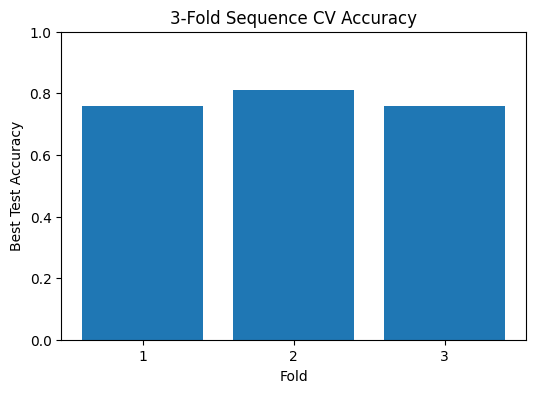

In [ ]:
import matplotlib.pyplot as plt

fold_ids = seq_summary["Fold"].tolist()
fold_accs = seq_summary["Best Test Accuracy"].tolist()

plt.figure(figsize=(6,4))
plt.bar([str(f) for f in fold_ids], fold_accs)
plt.xlabel("Fold")
plt.ylabel("Best Test Accuracy")
plt.title("3-Fold Sequence CV Accuracy")
plt.ylim(0, 1)
plt.show()

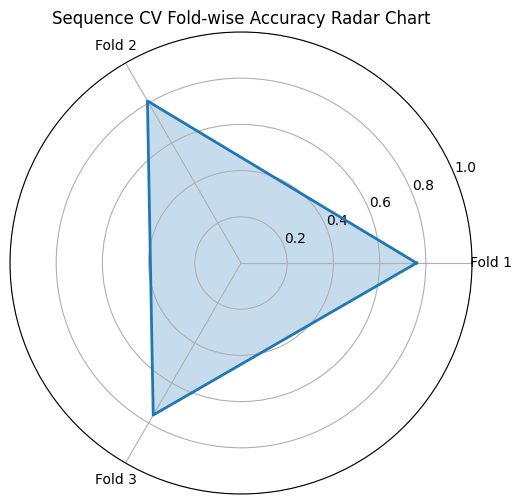

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

labels = [f"Fold {f}" for f in fold_ids]
values = fold_accs[:]

angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
values += values[:1]
angles += angles[:1]
labels += labels[:1]

fig = plt.figure(figsize=(6,6))
ax = plt.subplot(111, polar=True)
ax.plot(angles, values, linewidth=2)
ax.fill(angles, values, alpha=0.25)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels[:-1])
ax.set_title("Sequence CV Fold-wise Accuracy Radar Chart")
ax.set_ylim(0, 1)
plt.show()

In [ ]:
import torch
from torch.utils.data import DataLoader

seq_eval_results = []

for res in fold_results:
    fold_idx = res["fold"] - 1

    train_dataset = PersonIDDataset(scaled_folds[fold_idx]["train"], label_map)
    test_dataset = PersonIDDataset(scaled_folds[fold_idx]["test"], label_map)

    test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

    model = FinalPersonIDModel(len(label_map)).to(device)
    model.load_state_dict(res["best_model_state"])
    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for skeleton, anthro, gait, shape, label in test_loader:
            skeleton = skeleton.to(device)
            anthro = anthro.to(device)
            gait = gait.to(device)
            shape = shape.to(device)
            label = label.to(device)

            outputs = model(skeleton, anthro, gait, shape)
            preds = outputs.argmax(dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(label.cpu().numpy())

    seq_eval_results.append({
        "fold": res["fold"],
        "preds": all_preds,
        "labels": all_labels
    })

print("Stored fold-wise predictions for sequence CV.")

Stored fold-wise predictions for sequence CV.


In [ ]:
cm = confusion_matrix(all_labels, all_preds)

# normalize row-wise
cm_norm = cm.astype('float') / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(10, 10))

im = ax.imshow(cm_norm, interpolation='nearest')
plt.title("Normalized Confusion Matrix (3-Fold Sequence CV)", fontsize=14)

cbar = plt.colorbar(im, ax=ax)
cbar.ax.tick_params(labelsize=10)

tick_marks = np.arange(cm.shape[0])
ax.set_xticks(tick_marks)
ax.set_yticks(tick_marks)

ax.set_xlabel("Predicted Label", fontsize=12)
ax.set_ylabel("True Label", fontsize=12)

# show percentages
for i in range(cm_norm.shape[0]):
    for j in range(cm_norm.shape[1]):
        ax.text(j, i, f"{cm_norm[i, j]:.2f}",
                ha="center", va="center",
                color="white" if cm_norm[i, j] > 0.5 else "black",
                fontsize=8)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import classification_report

target_names = [f"Subject_{sid}" for sid in sorted(label_map.keys())]

report = classification_report(
    all_labels,
    all_preds,
    target_names=target_names,
    digits=4
)

print(report)

              precision    recall  f1-score   support

   Subject_1     0.7059    0.8000    0.7500        15
   Subject_2     0.8235    0.9333    0.8750        15
   Subject_3     0.7500    0.6000    0.6667        15
   Subject_4     0.7333    0.7333    0.7333        15
   Subject_7     0.7143    0.6667    0.6897        15
   Subject_8     0.6667    0.9333    0.7778        15
   Subject_9     0.8333    1.0000    0.9091        15
  Subject_11     0.6667    0.5333    0.5926        15
  Subject_12     0.9167    0.7333    0.8148        15
  Subject_13     0.7692    0.6667    0.7143        15
  Subject_14     0.8000    0.8000    0.8000        15
  Subject_15     0.9231    0.8000    0.8571        15
  Subject_16     0.9091    0.6667    0.7692        15
  Subject_17     1.0000    0.8667    0.9286        15
  Subject_19     0.6190    0.8667    0.7222        15
  Subject_20     0.7000    0.4667    0.5600        15
  Subject_21     0.7222    0.8667    0.7879        15
  Subject_22     0.7692    

In [ ]:
from sklearn.metrics import precision_recall_fscore_support
import pandas as pd

precision, recall, f1, support = precision_recall_fscore_support(all_labels, all_preds, zero_division=0)

metrics_df = pd.DataFrame({
    "Class": target_names,
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1,
    "Support": support
})

display(metrics_df)

,Class,Precision,Recall,F1-score,Support
0,Subject_1,0.705882,0.800000,0.750000,15
1,Subject_2,0.823529,0.933333,0.875000,15
2,Subject_3,0.750000,0.600000,0.666667,15
3,Subject_4,0.733333,0.733333,0.733333,15
4,Subject_7,0.714286,0.666667,0.689655,15
5,Subject_8,0.666667,0.933333,0.777778,15
6,Subject_9,0.833333,1.000000,0.909091,15
7,Subject_11,0.666667,0.533333,0.592593,15
8,Subject_12,0.916667,0.733333,0.814815,15
9,Subject_13,0.769231,0.666667,0.714286,15


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

acc = accuracy_score(all_labels, all_preds)
prec_macro = precision_score(all_labels, all_preds, average="macro", zero_division=0)
rec_macro = recall_score(all_labels, all_preds, average="macro", zero_division=0)
f1_macro = f1_score(all_labels, all_preds, average="macro", zero_division=0)

print(f"Accuracy        : {acc:.4f}")
print(f"Macro Precision : {prec_macro:.4f}")
print(f"Macro Recall    : {rec_macro:.4f}")
print(f"Macro F1-score  : {f1_macro:.4f}")

Accuracy        : 0.7767
Macro Precision : 0.7840
Macro Recall    : 0.7767
Macro F1-score  : 0.7723


Rank-1: 0.7767
Rank-3: 0.9133
Rank-5: 0.9700
Rank-10: 0.9933


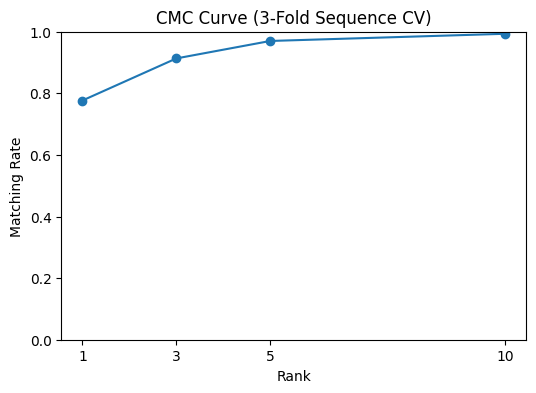

In [ ]:
import numpy as np
import torch
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

all_logits = []
all_true = []

for res in fold_results:
    fold_idx = res["fold"] - 1

    test_dataset = PersonIDDataset(scaled_folds[fold_idx]["test"], label_map)
    test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

    model = FinalPersonIDModel(len(label_map)).to(device)
    model.load_state_dict(res["best_model_state"])
    model.eval()

    with torch.no_grad():
        for skeleton, anthro, gait, shape, label in test_loader:
            skeleton = skeleton.to(device)
            anthro = anthro.to(device)
            gait = gait.to(device)
            shape = shape.to(device)

            outputs = model(skeleton, anthro, gait, shape)
            all_logits.append(outputs.cpu().numpy())
            all_true.append(label.numpy())

all_logits = np.concatenate(all_logits, axis=0)
all_true = np.concatenate(all_true, axis=0)

sorted_idx = np.argsort(-all_logits, axis=1)

ranks = [1, 3, 5, 10]
cmc_scores = []

for r in ranks:
    correct = 0
    for i in range(len(all_true)):
        if all_true[i] in sorted_idx[i, :r]:
            correct += 1
    cmc_scores.append(correct / len(all_true))

for r, s in zip(ranks, cmc_scores):
    print(f"Rank-{r}: {s:.4f}")

plt.figure(figsize=(6,4))
plt.plot(ranks, cmc_scores, marker='o')
plt.xlabel("Rank")
plt.ylabel("Matching Rate")
plt.title("CMC Curve (3-Fold Sequence CV)")
plt.xticks(ranks)
plt.ylim(0, 1)
plt.show()

In [ ]:
direction_list = ['frontal', 'left_lateral', 'right_lateral', 'left_diagonal', 'right_diagonal']

direction_folds = []

for d in direction_list:
    fold = {"train": [], "test": []}

    for item in processed_data:
        if item["direction"] == d:
            fold["test"].append(item)
        else:
            fold["train"].append(item)

    direction_folds.append(fold)

# check
for i, fold in enumerate(direction_folds):
    print(f"\nFold {i+1} → Test direction: {direction_list[i]}")
    print("Train size:", len(fold["train"]))
    print("Test size :", len(fold["test"]))


Fold 1 → Test direction: frontal
Train size: 240
Test size : 60

Fold 2 → Test direction: left_lateral
Train size: 240
Test size : 60

Fold 3 → Test direction: right_lateral
Train size: 240
Test size : 60

Fold 4 → Test direction: left_diagonal
Train size: 240
Test size : 60

Fold 5 → Test direction: right_diagonal
Train size: 240
Test size : 60


In [ ]:
import numpy as np
import torch
from torch.utils.data import Dataset

def normalize_orientation(sequence):
    seq = sequence.copy()

    for t in range(seq.shape[0]):
        frame = seq[t]

        left_shoulder = frame[4]
        right_shoulder = frame[8]

        direction = right_shoulder - left_shoulder
        angle = np.arctan2(direction[1], direction[0])

        c, s = np.cos(-angle), np.sin(-angle)

        R = np.array([
            [c, -s, 0],
            [s,  c, 0],
            [0,  0, 1]
        ], dtype=np.float32)

        seq[t] = frame @ R.T

    return seq.astype(np.float32)


class DirectionPersonIDDataset(Dataset):
    def __init__(self, samples, label_map, apply_orientation_norm=True):
        self.samples = samples
        self.label_map = label_map
        self.apply_orientation_norm = apply_orientation_norm

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        item = self.samples[idx]

        skeleton = item["skeleton"].copy()

        if self.apply_orientation_norm:
            skeleton = normalize_orientation(skeleton)

        skeleton = torch.tensor(skeleton, dtype=torch.float32)
        anthro = torch.tensor(item["anthro"], dtype=torch.float32)
        gait = torch.tensor(item["gait"], dtype=torch.float32)
        shape = torch.tensor(item["shape"], dtype=torch.float32)
        label = torch.tensor(self.label_map[item["subject"]], dtype=torch.long)

        return skeleton, anthro, gait, shape, label

In [ ]:
import copy
from sklearn.preprocessing import StandardScaler

scaled_direction_folds = []

for fold in direction_folds:
    fold_copy = {
        "train": [copy.deepcopy(item) for item in fold["train"]],
        "test": [copy.deepcopy(item) for item in fold["test"]]
    }

    train_anthro = np.array([item["anthro"] for item in fold_copy["train"]])
    train_gait   = np.array([item["gait"] for item in fold_copy["train"]])
    train_shape  = np.array([item["shape"] for item in fold_copy["train"]])

    scaler_a = StandardScaler().fit(train_anthro)
    scaler_g = StandardScaler().fit(train_gait)
    scaler_s = StandardScaler().fit(train_shape)

    for item in fold_copy["train"]:
        item["anthro"] = scaler_a.transform(item["anthro"].reshape(1, -1))[0].astype(np.float32)
        item["gait"]   = scaler_g.transform(item["gait"].reshape(1, -1))[0].astype(np.float32)
        item["shape"]  = scaler_s.transform(item["shape"].reshape(1, -1))[0].astype(np.float32)

    for item in fold_copy["test"]:
        item["anthro"] = scaler_a.transform(item["anthro"].reshape(1, -1))[0].astype(np.float32)
        item["gait"]   = scaler_g.transform(item["gait"].reshape(1, -1))[0].astype(np.float32)
        item["shape"]  = scaler_s.transform(item["shape"].reshape(1, -1))[0].astype(np.float32)

    scaled_direction_folds.append(fold_copy)

print("Scaled direction folds ready:", len(scaled_direction_folds))

Scaled direction folds ready: 5


In [ ]:
direction_results = []

for fold_idx in range(5):
    print("=" * 60)
    print(f"Direction Fold {fold_idx+1}: Test = {direction_list[fold_idx]}")
    print("=" * 60)

    train_dataset = DirectionPersonIDDataset(
        scaled_direction_folds[fold_idx]["train"], label_map, apply_orientation_norm=True
    )
    test_dataset = DirectionPersonIDDataset(
        scaled_direction_folds[fold_idx]["test"], label_map, apply_orientation_norm=True
    )

    train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

    model = FinalPersonIDModel(len(label_map)).to(device)

    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = torch.optim.Adam(model.parameters(), lr=5e-4, weight_decay=1e-4)

    best_acc = 0.0
    best_preds = None
    best_labels = None

    for epoch in range(num_epochs):
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        test_loss, test_acc, all_preds, all_labels = evaluate(model, test_loader, criterion, device)

        if test_acc > best_acc:
            best_acc = test_acc
            best_preds = all_preds
            best_labels = all_labels

    direction_results.append({
        "direction": direction_list[fold_idx],
        "accuracy": best_acc,
        "preds": best_preds,
        "labels": best_labels
    })

    print(f"Best Accuracy: {best_acc:.4f}")

Direction Fold 1: Test = frontal
Best Accuracy: 0.7000
Direction Fold 2: Test = left_lateral
Best Accuracy: 0.5000
Direction Fold 3: Test = right_lateral
Best Accuracy: 0.4667
Direction Fold 4: Test = left_diagonal
Best Accuracy: 0.4333
Direction Fold 5: Test = right_diagonal
Best Accuracy: 0.6500


In [ ]:
accs = [x["accuracy"] for x in direction_results]

print("\nDirection-wise Accuracy:")
for x in direction_results:
    print(f"{x['direction']}: {x['accuracy']:.4f}")

print("\nMean Accuracy:", np.mean(accs))
print("Std Dev:", np.std(accs))


Direction-wise Accuracy:
frontal: 0.7000
left_lateral: 0.5000
right_lateral: 0.4667
left_diagonal: 0.4333
right_diagonal: 0.6500

Mean Accuracy: 0.5499999999999999
Std Dev: 0.10540925533894598


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np

fold_precisions = []
fold_recalls = []
fold_f1s = []

print("Fold-wise Metrics:\n")

for res in direction_results:
    y_true = np.array(res["labels"])
    y_pred = np.array(res["preds"])

    prec = precision_score(y_true, y_pred, average="weighted", zero_division=0)
    rec  = recall_score(y_true, y_pred, average="weighted", zero_division=0)
    f1   = f1_score(y_true, y_pred, average="weighted", zero_division=0)

    fold_precisions.append(prec)
    fold_recalls.append(rec)
    fold_f1s.append(f1)

    print(f"{res['direction']}")
    print(f"  Precision: {prec:.4f}")
    print(f"  Recall   : {rec:.4f}")
    print(f"  F1-score : {f1:.4f}")
    print("-" * 40)

print("\nAverage Metrics Across 5 Folds:")
print(f"Mean Precision: {np.mean(fold_precisions):.4f}")
print(f"Mean Recall   : {np.mean(fold_recalls):.4f}")
print(f"Mean F1-score : {np.mean(fold_f1s):.4f}")

Fold-wise Metrics:

frontal
  Precision: 0.6864
  Recall   : 0.7000
  F1-score : 0.6480
----------------------------------------
left_lateral
  Precision: 0.4978
  Recall   : 0.5000
  F1-score : 0.4543
----------------------------------------
right_lateral
  Precision: 0.4197
  Recall   : 0.4667
  F1-score : 0.4059
----------------------------------------
left_diagonal
  Precision: 0.3858
  Recall   : 0.4333
  F1-score : 0.3839
----------------------------------------
right_diagonal
  Precision: 0.6233
  Recall   : 0.6500
  F1-score : 0.6058
----------------------------------------

Average Metrics Across 5 Folds:
Mean Precision: 0.5226
Mean Recall   : 0.5500
Mean F1-score : 0.4996


In [ ]:
from sklearn.metrics import classification_report

for res in direction_results:
    y_true = np.array(res["labels"])
    y_pred = np.array(res["preds"])

    print("=" * 60)
    print(f"Classification Report: {res['direction']}")
    print("=" * 60)
    print(classification_report(y_true, y_pred, zero_division=0))

Classification Report: frontal
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         3
           1       1.00      0.33      0.50         3
           2       0.00      0.00      0.00         3
           3       0.43      1.00      0.60         3
           4       1.00      0.33      0.50         3
           5       1.00      1.00      1.00         3
           6       1.00      1.00      1.00         3
           7       1.00      0.33      0.50         3
           8       0.60      1.00      0.75         3
           9       0.50      1.00      0.67         3
          10       1.00      1.00      1.00         3
          11       1.00      1.00      1.00         3
          12       0.00      0.00      0.00         3
          13       1.00      0.67      0.80         3
          14       0.60      1.00      0.75         3
          15       0.25      0.33      0.29         3
          16       0.75      1.00      0.86       

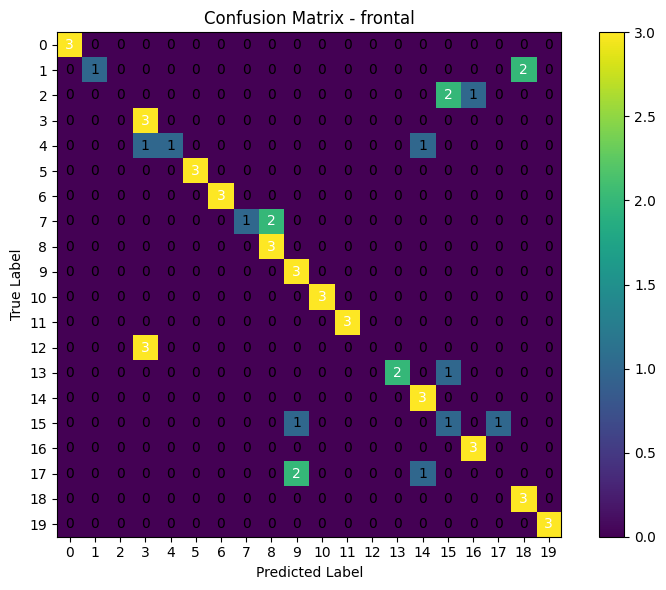

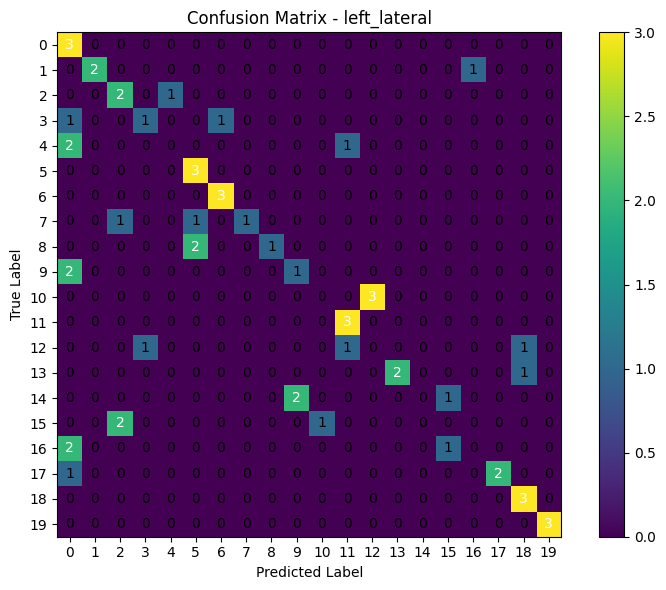

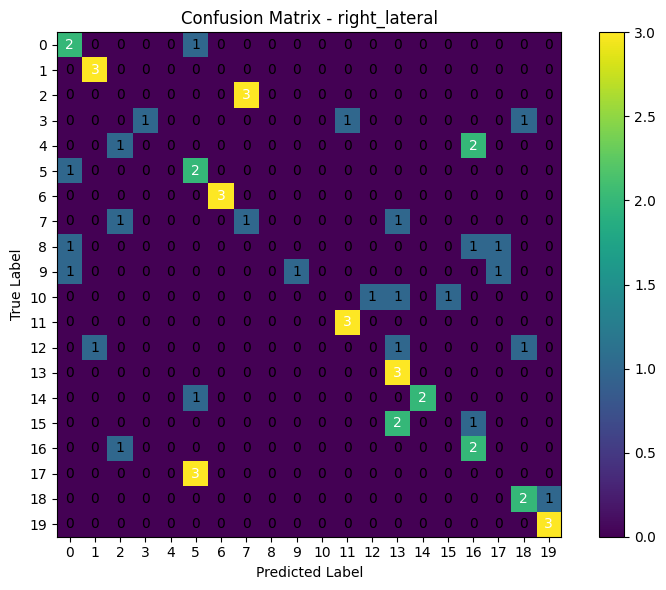

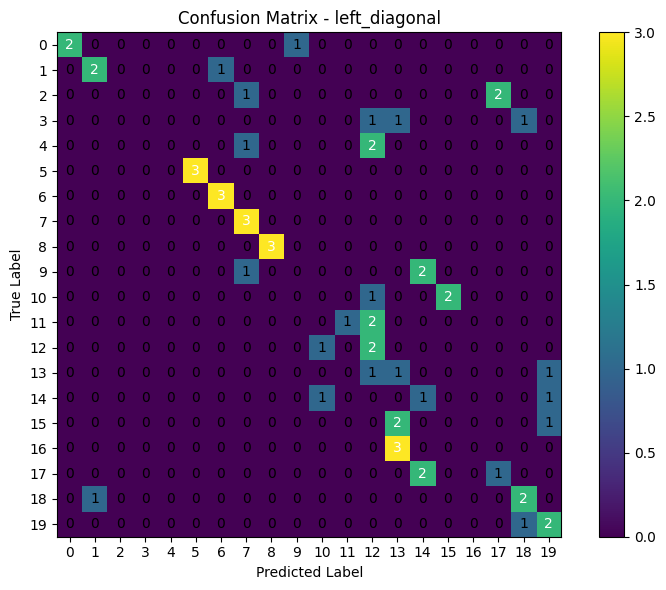

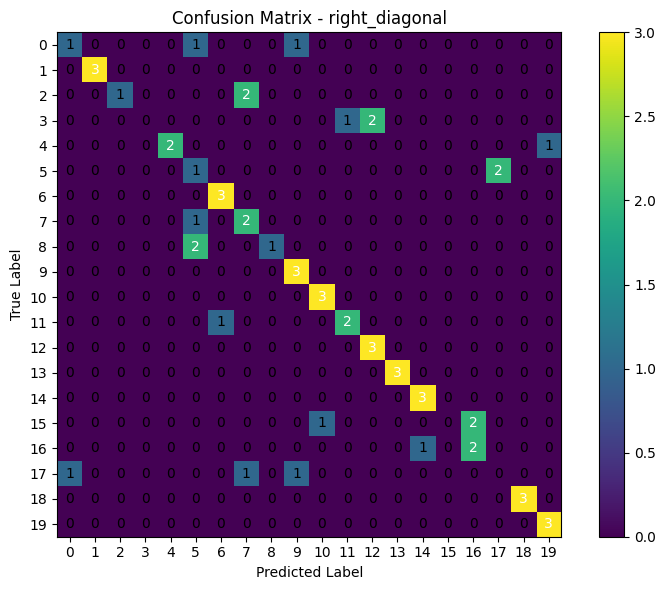

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

for res in direction_results:
    y_true = np.array(res["labels"])
    y_pred = np.array(res["preds"])

    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(8, 6))
    im = plt.imshow(cm, interpolation='nearest')
    plt.title(f"Confusion Matrix - {res['direction']}")

    # ADD COLORBAR (this is what you want)
    plt.colorbar(im)

    tick_marks = np.arange(len(np.unique(y_true)))
    plt.xticks(tick_marks)
    plt.yticks(tick_marks)

    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(j, i, cm[i, j],
                     ha="center", va="center",
                     color="white" if cm[i, j] > cm.max()/2 else "black")

    plt.tight_layout()
    plt.show()

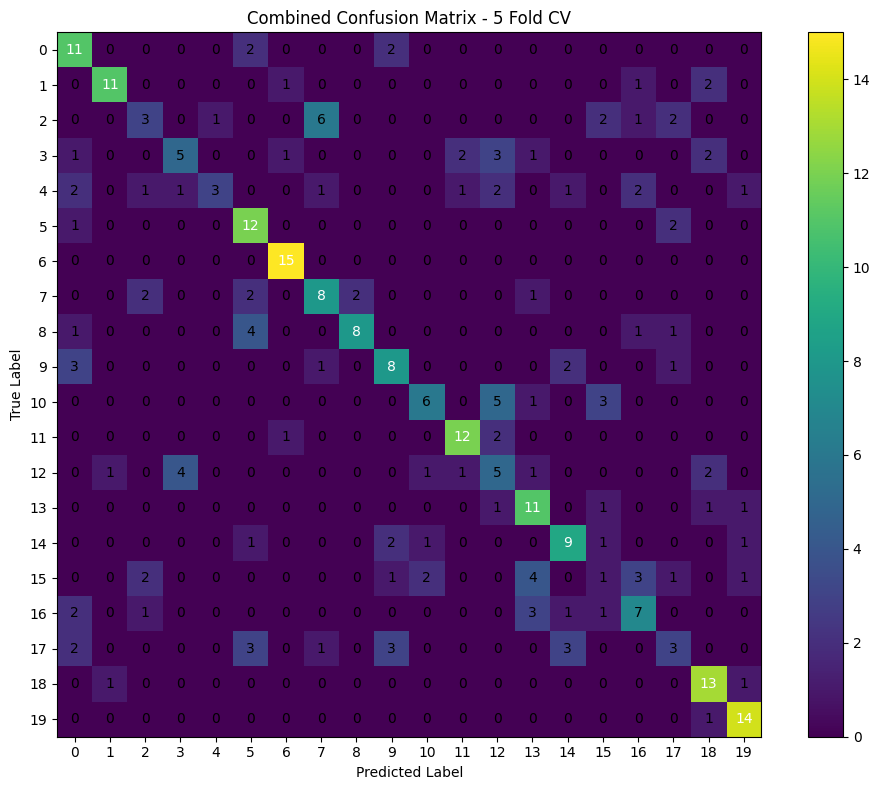

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

all_true = np.concatenate([np.array(res["labels"]) for res in direction_results])
all_pred = np.concatenate([np.array(res["preds"]) for res in direction_results])

cm = confusion_matrix(all_true, all_pred)

plt.figure(figsize=(10, 8))
im = plt.imshow(cm, interpolation='nearest')
plt.title("Combined Confusion Matrix - 5 Fold CV")

# COLORBAR
plt.colorbar(im)

tick_marks = np.arange(len(np.unique(all_true)))
plt.xticks(tick_marks)
plt.yticks(tick_marks)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j],
                 ha="center", va="center",
                 color="white" if cm[i, j] > cm.max()/2 else "black")

plt.tight_layout()
plt.show()

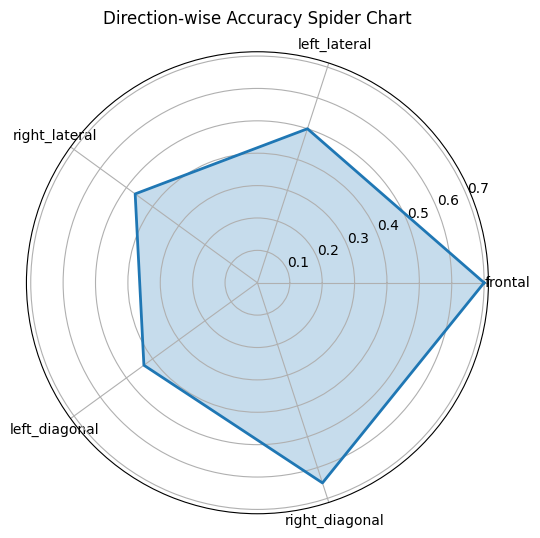

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

labels = [res["direction"] for res in direction_results]
values = [res["accuracy"] for res in direction_results]

num_vars = len(labels)

angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
values += values[:1]
angles += angles[:1]
labels += labels[:1]

fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))
ax.plot(angles, values, linewidth=2)
ax.fill(angles, values, alpha=0.25)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels[:-1])
ax.set_title("Direction-wise Accuracy Spider Chart", pad=20)

plt.show()

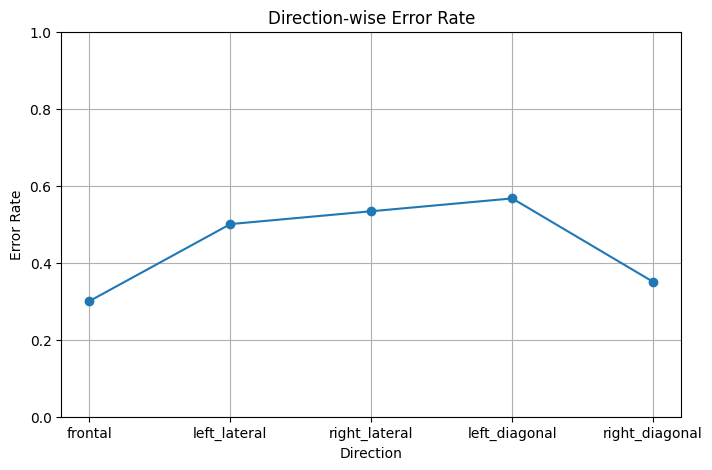

In [ ]:
import matplotlib.pyplot as plt

directions = [res["direction"] for res in direction_results]
error_rates = [1 - res["accuracy"] for res in direction_results]

plt.figure(figsize=(8, 5))
plt.plot(directions, error_rates, marker='o')
plt.ylabel("Error Rate")
plt.xlabel("Direction")
plt.title("Direction-wise Error Rate")
plt.ylim(0, 1)
plt.grid(True)
plt.show()

In [ ]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np

rows = []

for res in direction_results:
    y_true = np.array(res["labels"])
    y_pred = np.array(res["preds"])

    rows.append({
        "Direction": res["direction"],
        "Accuracy": res["accuracy"],
        "Precision": precision_score(y_true, y_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_true, y_pred, average="weighted", zero_division=0),
        "F1-score": f1_score(y_true, y_pred, average="weighted", zero_division=0)
    })

df_metrics = pd.DataFrame(rows)
display(df_metrics)

print("\nAverage Values:")
print(df_metrics.mean(numeric_only=True))

,Direction,Accuracy,Precision,Recall,F1-score
0,frontal,0.700000,0.686429,0.700000,0.647976
1,left_lateral,0.500000,0.497803,0.500000,0.454286
2,right_lateral,0.466667,0.419702,0.466667,0.405924
3,left_diagonal,0.433333,0.385754,0.433333,0.383929
4,right_diagonal,0.650000,0.623333,0.650000,0.605833



Average Values:
Accuracy     0.550000
Precision    0.522604
Recall       0.550000
F1-score     0.499589
dtype: float64
